In [13]:
# 1. 导入所需库
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns



In [14]:

# === 解决中文显示问题 ===
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 黑体
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号


In [15]:
# 2. 加载鸢尾花数据集
iris = datasets.load_iris()
X = iris.data  # 特征：4维
y = iris.target  # 标签：0,1,2



In [18]:
# 3. 划分训练集和测试集（80%训练，20%测试）
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



准确率: 0.90

分类报告:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



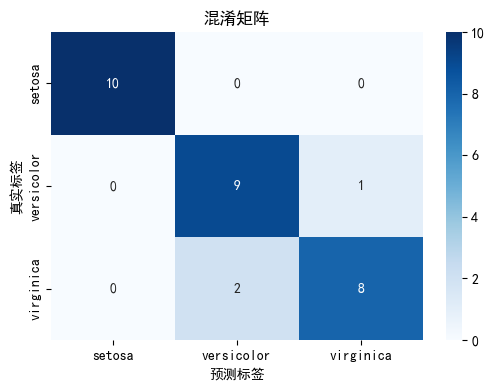

In [17]:
# 4. 创建并训练 SVM 模型（使用 RBF 核）
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')  # C: 正则化参数，gamma: RBF核参数
svm_model.fit(X_train, y_train)

# 5. 预测
y_pred = svm_model.predict(X_test)

# 6. 评估模型
accuracy = accuracy_score(y_test, y_pred)
print(f"准确率: {accuracy:.2f}")
print("\n分类报告:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# 7. 混淆矩阵可视化
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title('混淆矩阵')
plt.ylabel('真实标签')
plt.xlabel('预测标签')
plt.show()

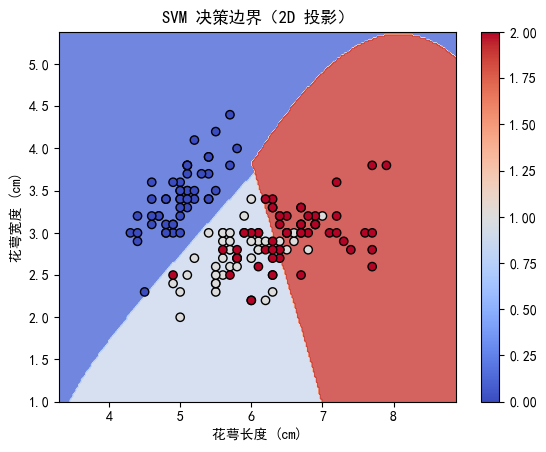

In [6]:
# 只取前两个特征用于可视化
X_vis = iris.data[:, :2]  # 花萼长度 & 宽度
y_vis = iris.target

# 重新划分
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X_vis, y_vis, test_size=0.2, random_state=42
)

# 训练 2D SVM
svm_2d = SVC(kernel='rbf', C=1.0)
svm_2d.fit(X_train_v, y_train_v)

# 创建网格用于绘制决策边界
def plot_decision_boundary(model, X, y):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.coolwarm)
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
    plt.xlabel('花萼长度 (cm)')
    plt.ylabel('花萼宽度 (cm)')
    plt.title('SVM 决策边界（2D 投影）')
    plt.colorbar(scatter)
    plt.show()

plot_decision_boundary(svm_2d, X_vis, y_vis)